# Objectif 

Illustration d'une méthode d'interpolation de la librairie basée sur la réduction de dimension par apprentissage de variété par la méthode ISOMAP. 

Le guide d'onde est un guide d'onde de Pekeris, constitué donc de deux couches fluides dont les propriétés sont les suivantes : 
* dans la colonne d'eau :
    * $c_0 = 1500 m/s$
    * $\rho_0 = 1000 kg/m^3$
* dans le sédiment : 
    * $c_1 = 1600 m/s$
    * $\rho_1 = 1500 kg/m^3$

In [1]:
import sys
import numpy as np

In [2]:
root_project = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
sys.path.append(root_project)

from illustration_rtf.src.sensitivity import (
    baseline_env,
    baseline_sig,
    baseline_src_rcv,
    calc_gamma_dist,
    calc_mainlobe_width_3dB,
    calc_monotonicity_domain, 
    # run_single_sensibility_test,
)
from source.normal_modes import * 
from publication.publication_figure import color, set_subfigures_abc_labels

# Chargement de l'environnement 

In [3]:
# Environment
env_param = baseline_env()
print("Baseline environement properties:")
for k in env_param.keys():
    print(f"\t{k} = {env_param[k]}")

# Signal
sig_param = baseline_sig()
print("Baseline signal properties:")
for k in sig_param.keys():
    print(f"\t{k} = {sig_param[k]}")

# Source receiver config
src_rcv_param = baseline_src_rcv()
print("Baseline src / rcv configuration:")
for k in src_rcv_param.keys():
    print(f"\t{k} = {src_rcv_param[k]}")

# Environment
c1 = env_param.get("c1", None)
c2 = env_param.get("c2", None)
rho1 = env_param.get("rho1", None)
rho2 = env_param.get("rho2", None)
attn2 = env_param.get("attn2", None)
d = env_param.get("depth", None)

# Signal
freq = sig_param.get("freq", None)
fs = sig_param.get("fs", None)
fmax = sig_param.get("fmax", None)

# Source / receiver
z_s = src_rcv_param.get("z_s", 5)
z = src_rcv_param.get("z_rcv", 20)
# r_grid = src_rcv_param.get("r_rcv", np.array([1e4]))
r_grid = np.arange(5 * 1e3, 25 * 1e3 + 50, 50)

r0 = src_rcv_param.get("r0", 1e4)
d12 = src_rcv_param.get("d12", 100)

Baseline environement properties:
	c1 = 1500
	c2 = 1600
	rho1 = 1000.0
	rho2 = 1800.0
	attn2 = 0.8
	depth = 100
Baseline signal properties:
	freq = [  0.    0.2   0.4   0.6   0.8   1.    1.2   1.4   1.6   1.8   2.    2.2
   2.4   2.6   2.8   3.    3.2   3.4   3.6   3.8   4.    4.2   4.4   4.6
   4.8   5.    5.2   5.4   5.6   5.8   6.    6.2   6.4   6.6   6.8   7.
   7.2   7.4   7.6   7.8   8.    8.2   8.4   8.6   8.8   9.    9.2   9.4
   9.6   9.8  10.   10.2  10.4  10.6  10.8  11.   11.2  11.4  11.6  11.8
  12.   12.2  12.4  12.6  12.8  13.   13.2  13.4  13.6  13.8  14.   14.2
  14.4  14.6  14.8  15.   15.2  15.4  15.6  15.8  16.   16.2  16.4  16.6
  16.8  17.   17.2  17.4  17.6  17.8  18.   18.2  18.4  18.6  18.8  19.
  19.2  19.4  19.6  19.8  20.   20.2  20.4  20.6  20.8  21.   21.2  21.4
  21.6  21.8  22.   22.2  22.4  22.6  22.8  23.   23.2  23.4  23.6  23.8
  24.   24.2  24.4  24.6  24.8  25.   25.2  25.4  25.6  25.8  26.   26.2
  26.4  26.6  26.8  27.   27.2  27.4  27.6  27.8  2

# Jeu de données sur une grille 2D 

In [4]:
xmin = 10000
xmax = 13000
ymin = 3000
ymax = 6000

dx = 200
dy = 200
x = np.arange(xmin, xmax + dx, dx)
y = np.arange(ymin, ymax + dy, dy)
xx, yy = np.meshgrid(x, y)
x_rcv1, y_rcv1 = -d12/2, 0
x_rcv2, y_rcv2 = d12/2, 0
rr1 = np.sqrt((xx - x_rcv1) ** 2 + (yy - y_rcv1) ** 2)
rr2 = np.sqrt((xx - x_rcv2) ** 2 + (yy - y_rcv2) ** 2)

x0, y0 = 11500, 4500
r10 = np.sqrt((x0 - x_rcv1) ** 2 + (y0 - y_rcv1) ** 2)
r20 = np.sqrt((x0 - x_rcv2) ** 2 + (y0 - y_rcv2) ** 2)
r0 = np.sqrt(x0**2 + y0**2)

In [45]:
rr1.shape, gamma_21_rr.shape

((16, 16), (751, 256))

In [6]:
# Green's fct on the 2D grid
rr1_flat = rr1.flatten()
gf_rr1 = pekeris_green_fct(freq, c1, c2, rho1, rho2, attn2, d, z_s, z, rr1_flat)
rr2_flat = rr2.flatten()
gf_rr2 = pekeris_green_fct(freq, c1, c2, rho1, rho2, attn2, d, z_s, z, rr2_flat)

# Green's fct at x0, y0
gf_r10 = pekeris_green_fct(freq, c1, c2, rho1, rho2, attn2, d, z_s, z, r10)
gf_r20 = pekeris_green_fct(freq, c1, c2, rho1, rho2, attn2, d, z_s, z, r20)

# Gamma
pi_21_rr = gf_rr2 / gf_rr1
pi_21_r0 = gf_r20 / gf_r10
gamma_21_rr = 20 * np.log10(np.abs(pi_21_rr))
gamma_21_r0 = 20 * np.log10(np.abs(pi_21_r0))

# Intercorr
c21_rr = gf_rr1 * np.conj(gf_rr2)
c21_r0 = gf_r10 * np.conj(gf_r20)

C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:326: RuntimeWarning: invalid value encountered in sqrt
  idx_krm_lt_k2, np.sqrt(k2**2 - krm**2), 1j * np.sqrt(krm**2 - k2**2)
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:618: RuntimeWarning: divide by zero encountered in divide
  lambd = c / f
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:582: RuntimeWarning: invalid value encountered in divide
  (1j * alpha_2_2d * omega_2d)
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:518: RuntimeWarning: invalid value encountered in sqrt
  / np.sqrt(krm[..., np.newaxis])
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:516: RuntimeWarning: invalid value encountered in divide
  Am[..., np.newaxis]
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28956\2437879825.py:12: RuntimeWarning: invalid value encountered in divide
  pi_21_rr = gf_rr2 / gf_rr1
C:\Users\baptiste.menetrier\AppData\L

In [46]:
gamma_21_rr.shape

(751, 256)

In [7]:
dist_c = np.abs(
    np.nansum(
        c21_r0 * np.conj(c21_rr),
        axis=0,
    )
)
dist_c /= np.max(dist_c)
dist_c = 1 - dist_c

In [8]:
dist_L1 = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L1"
)
dist_L2 = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L2"
)
# Calc theta with gamma
dist_theta_gamma = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="theta"
)
# With abs(pi)
# dist_theta_gamma = calc_gamma_dist(
#     gamma_a=np.abs(pi_21_r0), gamma_b=np.abs(pi_21_rr), dist_type="theta"
# )

# Calc theta with pi
inner_prod = np.nansum(pi_21_r0 * np.conj(pi_21_rr), axis=0)
norm_a = np.sqrt(np.nansum(pi_21_r0 * np.conj(pi_21_r0), axis=0))
norm_b = np.sqrt(np.nansum(pi_21_rr * np.conj(pi_21_rr), axis=0))
# Clip to [-1, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_theta = 1 - cos_angle  #  to [0, 1]
# dist = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

dist_L1 /= np.max(dist_L1)
dist_L2 /= np.max(dist_L2)
# # NOTE Should we normalize ? -> for a fair comparison each dist must have the same dynamic range ? 
dist_theta /= np.max(dist_theta)
dist_theta_gamma /= np.max(dist_theta_gamma)

In [9]:
# reshape
dist_theta_gamma = dist_theta_gamma.reshape(rr1.shape)
dist_theta = dist_theta.reshape(rr1.shape)
dist_c = dist_c.reshape(rr1.shape)
# Get min
ind_min = np.argmin(dist_theta)
xmin, ymin = xx.flatten()[ind_min], yy.flatten()[ind_min]
ind_min_gamma = np.argmin(dist_theta_gamma)
xmin_gamma, ymin_gamma = xx.flatten()[ind_min_gamma], yy.flatten()[ind_min_gamma]
ind_min_c = np.argmin(dist_c)
xmin_c, ymin_c = xx.flatten()[ind_min_c], yy.flatten()[ind_min_c]

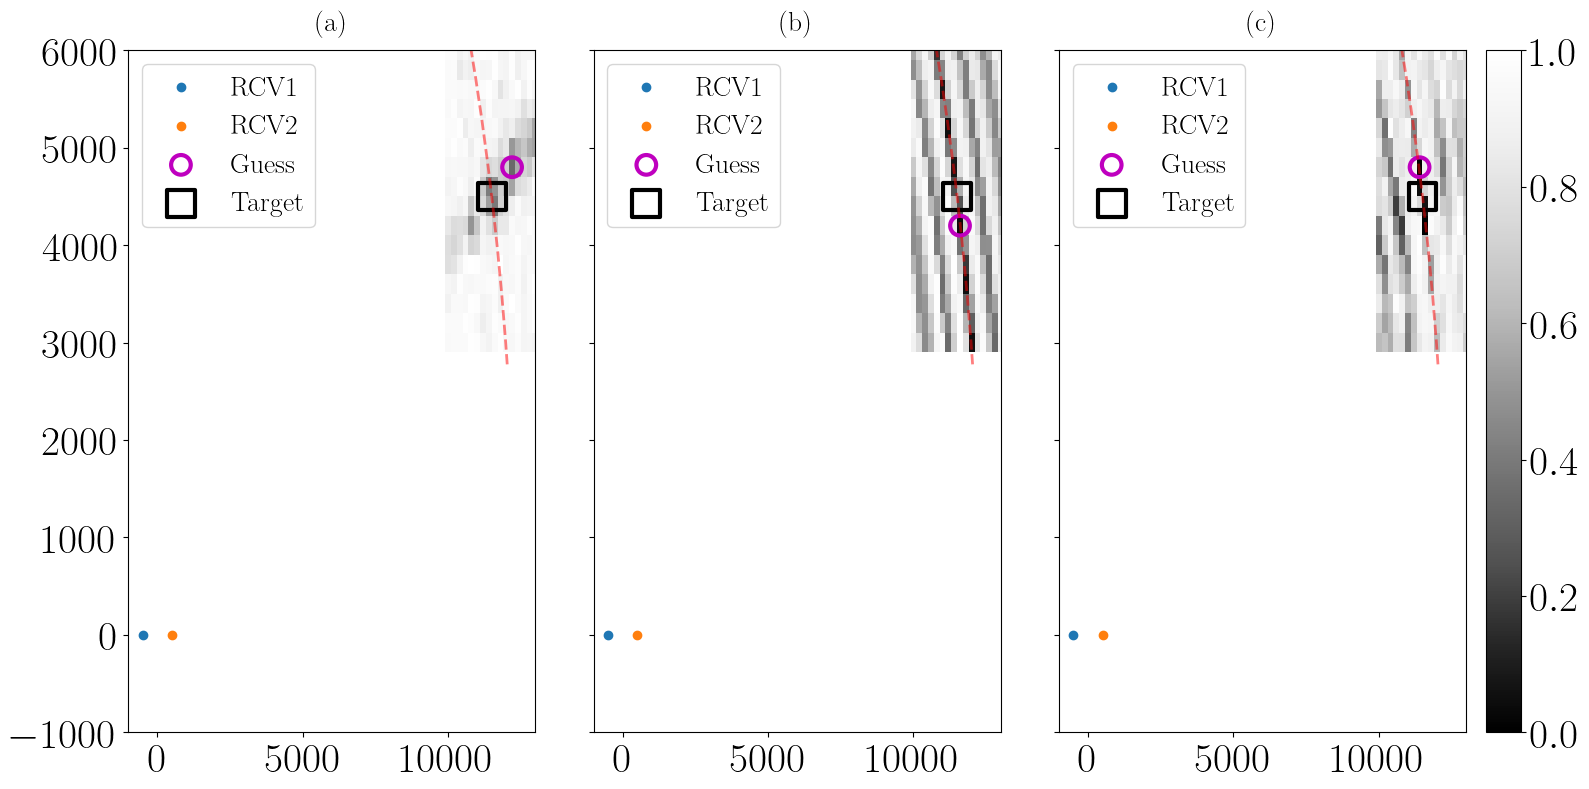

In [10]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 3, figsize=(16, 8), sharex=True, sharey=True)

im = axs[0].pcolormesh(x, y, dist_theta, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")

axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")

axs[0].scatter(
    xmin,
    ymin,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)

axs[0].legend(loc="upper left")

im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[1].scatter(
    xmin_gamma,
    ymin_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[1].legend(loc="upper left")



im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

axs[2].scatter(
    xmin_c,
    ymin_c,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[2].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)

axs[2].legend(loc="upper left")

plt.xlim(-d12, np.max(x))

plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2*r0,
        height=2*r0,
        angle=0,
        theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
        theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--"
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

Meilleures performances dans le cas de l'utilisation du rapport de fonction de transfert complexe (a), la restriction au module via l'utilisation de la quantité gamma réduit le contraste et engendre un lobe principale étendue (b), la méthode DCF présente des lobes images. 

In [11]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

# ISOMAP
n_components = 100
n_neighbors = 5
p = 2

# Define isomap object
# With Minkowski distance (equivalent to euclidean distance for p = 2)
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    p=p,
)
# # With cosine distance
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors,
#     n_components=n_components,
#     metric="cosine"
# )

data = gamma_21_rr.T  # (n_sample, n_features) = (n_pos, nfreq)
# Subsample
# data = data[::2, :]

# Remove nan
idx_f_no_nan = ~np.isnan(data[0, :])
data = data[:, idx_f_no_nan]

# Learn manifold and project data in target dimension

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# RQ : les résultats sont identiques si pas de standardisation des données
# X_scaled = data

# Project
coords = isomap_obj.fit_transform(X_scaled)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28956\1006218923.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


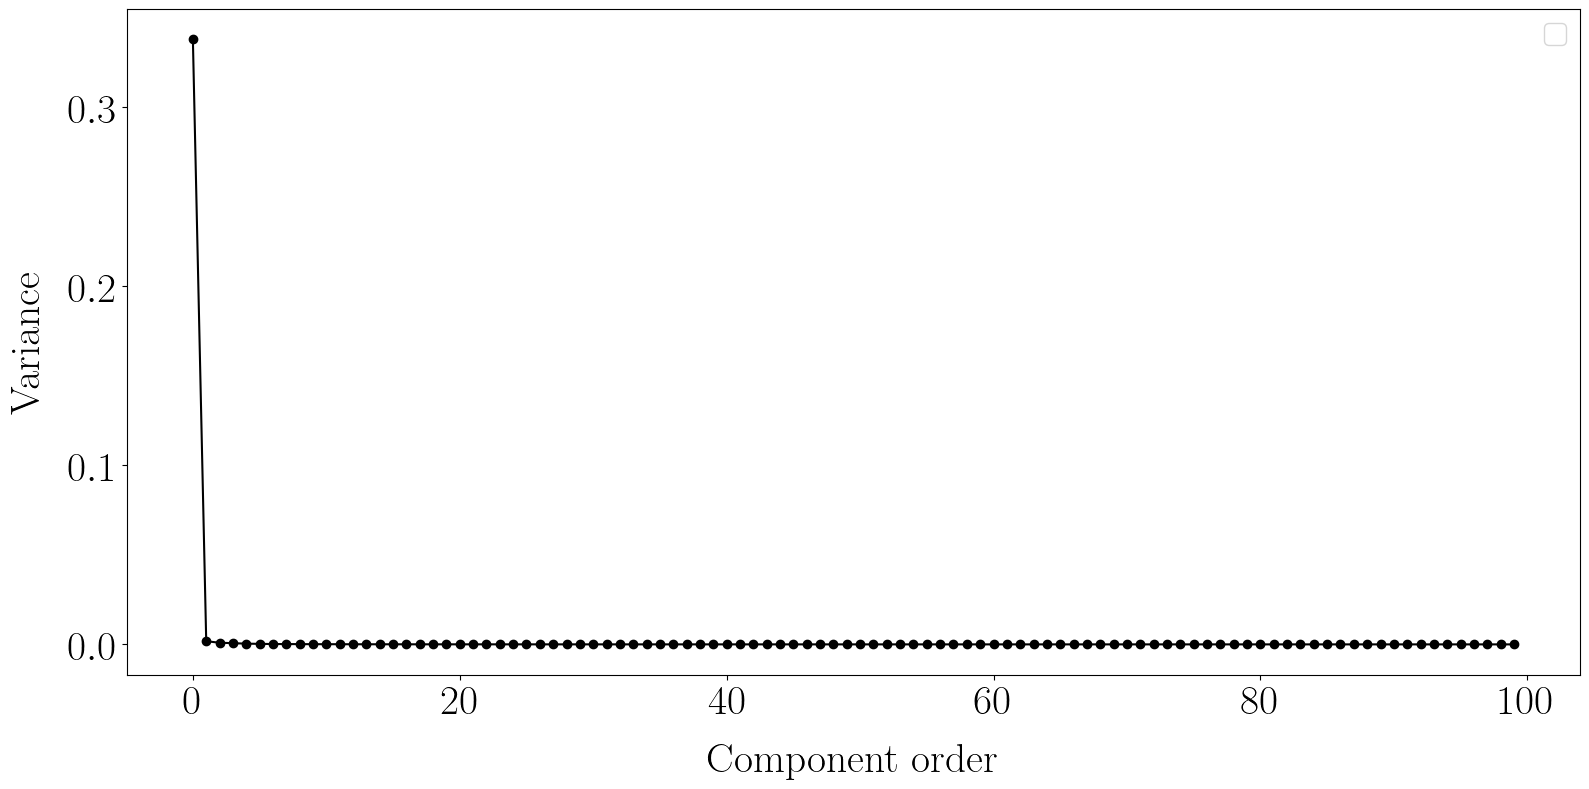

In [12]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28956\4181134354.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


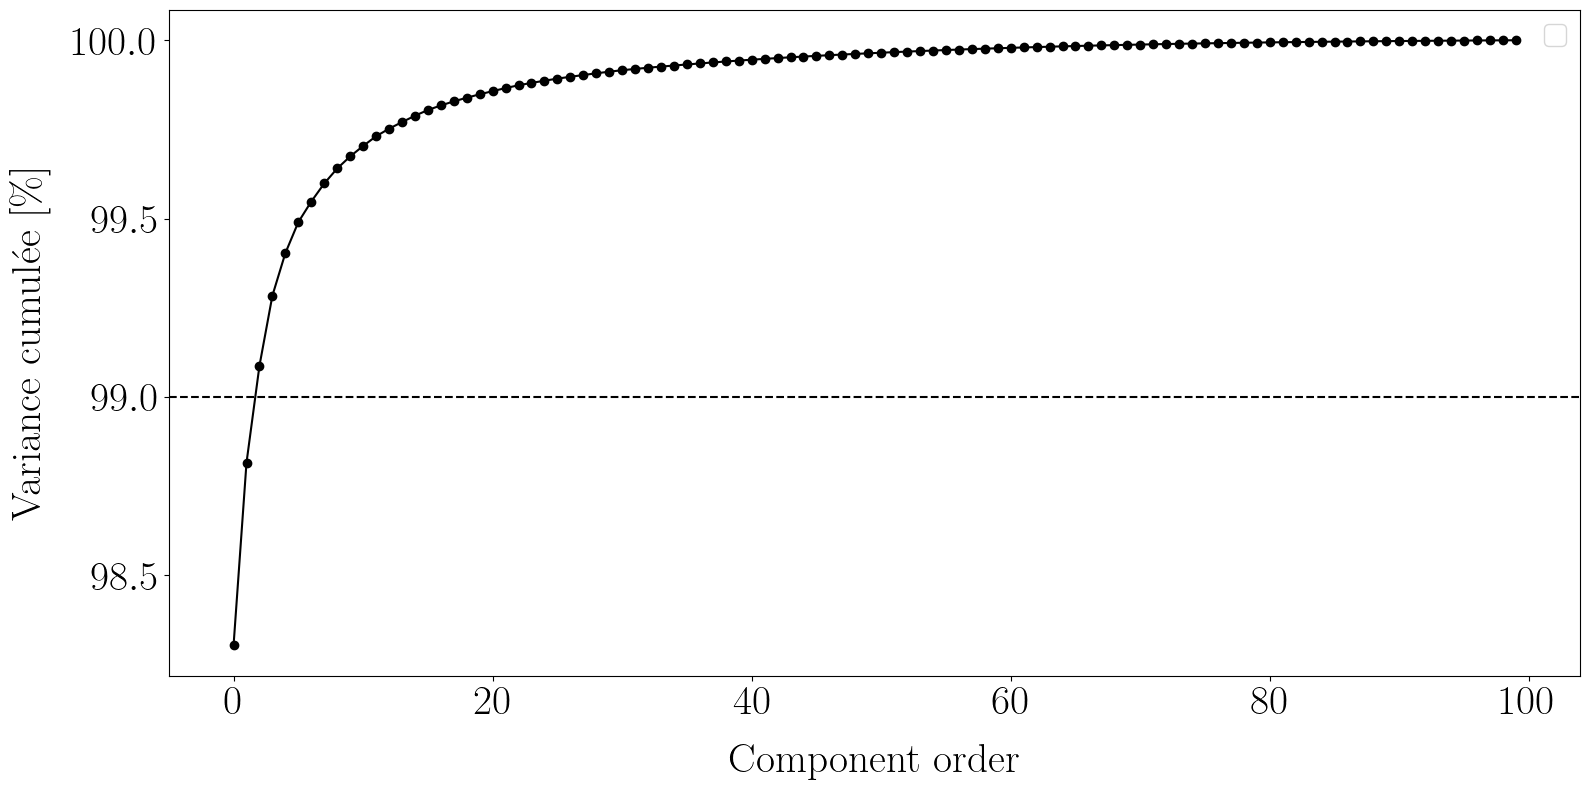

In [13]:
cvar_tot = np.sum(cvar)
cvar_ratio = cvar / cvar_tot
cum_cvar = np.cumsum(cvar_ratio)

# Variance cumulée
cumulative_variance_threshold = 99
plt.figure()
plt.plot(np.arange(cvar.size), cum_cvar * 100, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance cumulée [\%]")
plt.axhline(cumulative_variance_threshold, linestyle="--", color="k")
plt.legend()

In [14]:
# Compute info
cum_cvar_3D = cum_cvar[2]
# Determine the number of components needed to reach the threshold
nb_comp_th = np.argmax(cum_cvar * 100 >= cumulative_variance_threshold) + 1
# Get dimension ratio
dim_ratio = nb_comp_th / data.shape[1]

print(
    f"\tPercentage of explained variance by the first 3 components = {cum_cvar_3D*100:.1f}%"
)
print(
    f"\tNumber of components needed to reach the threshold ({cumulative_variance_threshold} %) = {nb_comp_th:.0f}"
)
print(f"\tDataset reduction of {(1 - dim_ratio)*100:.3f} %")

	Percentage of explained variance by the first 3 components = 99.1%
	Number of components needed to reach the threshold (99 %) = 3
	Dataset reduction of 99.570 %


### Allure des composantes 

In [15]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr.T  # (n_sample, n_features) = (n_pos, nfreq)

# Subsample
# gamma_ = gamma_[::10, :]

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# ### RTF (Pi) ###
# Learn manifold and project data in target dimension
pi_21_rr_ = pi_21_rr.T  # (n_pos, nfreq)

# Calc theta with pi
inner_prod = np.nansum(
    pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
)
norm_a = np.sqrt(
    np.nansum(
        pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[np.newaxis, :, :], axis=-1
    )
)
norm_b = np.sqrt(
    np.nansum(
        pi_21_rr_[:, np.newaxis, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
    )
)
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

### DCF ###
c12_ = c21_rr.T
# Subsample to reduce memory
# c12_ = c12_[::2, :]
dist_mat = np.abs(
    np.nansum(
        c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
        axis=-1,
    )
)
dist_mat = dist_mat / np.max(dist_mat)
dist_mat_dcf = 1 - dist_mat

In [16]:
n_components = 5
n_neighbors = 10
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# ### RTF (Pi) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isompa_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
coords_isompa_pi = coords_isompa_pi / np.max(np.abs(coords_isompa_pi))

# ### DCF ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isompa_dcf = isomap_obj.fit_transform(dist_mat_dcf)
coords_isompa_dcf = coords_isompa_dcf / np.max(np.abs(coords_isompa_dcf))

In [17]:
# Reshape coords to 2D grid
shape = rr1.shape + (n_components,)
coords_isomap_gamma = coords_isomap_gamma.reshape(shape)
coords_isompa_pi = coords_isompa_pi.reshape(shape)
coords_isompa_dcf = coords_isompa_dcf.reshape(shape)

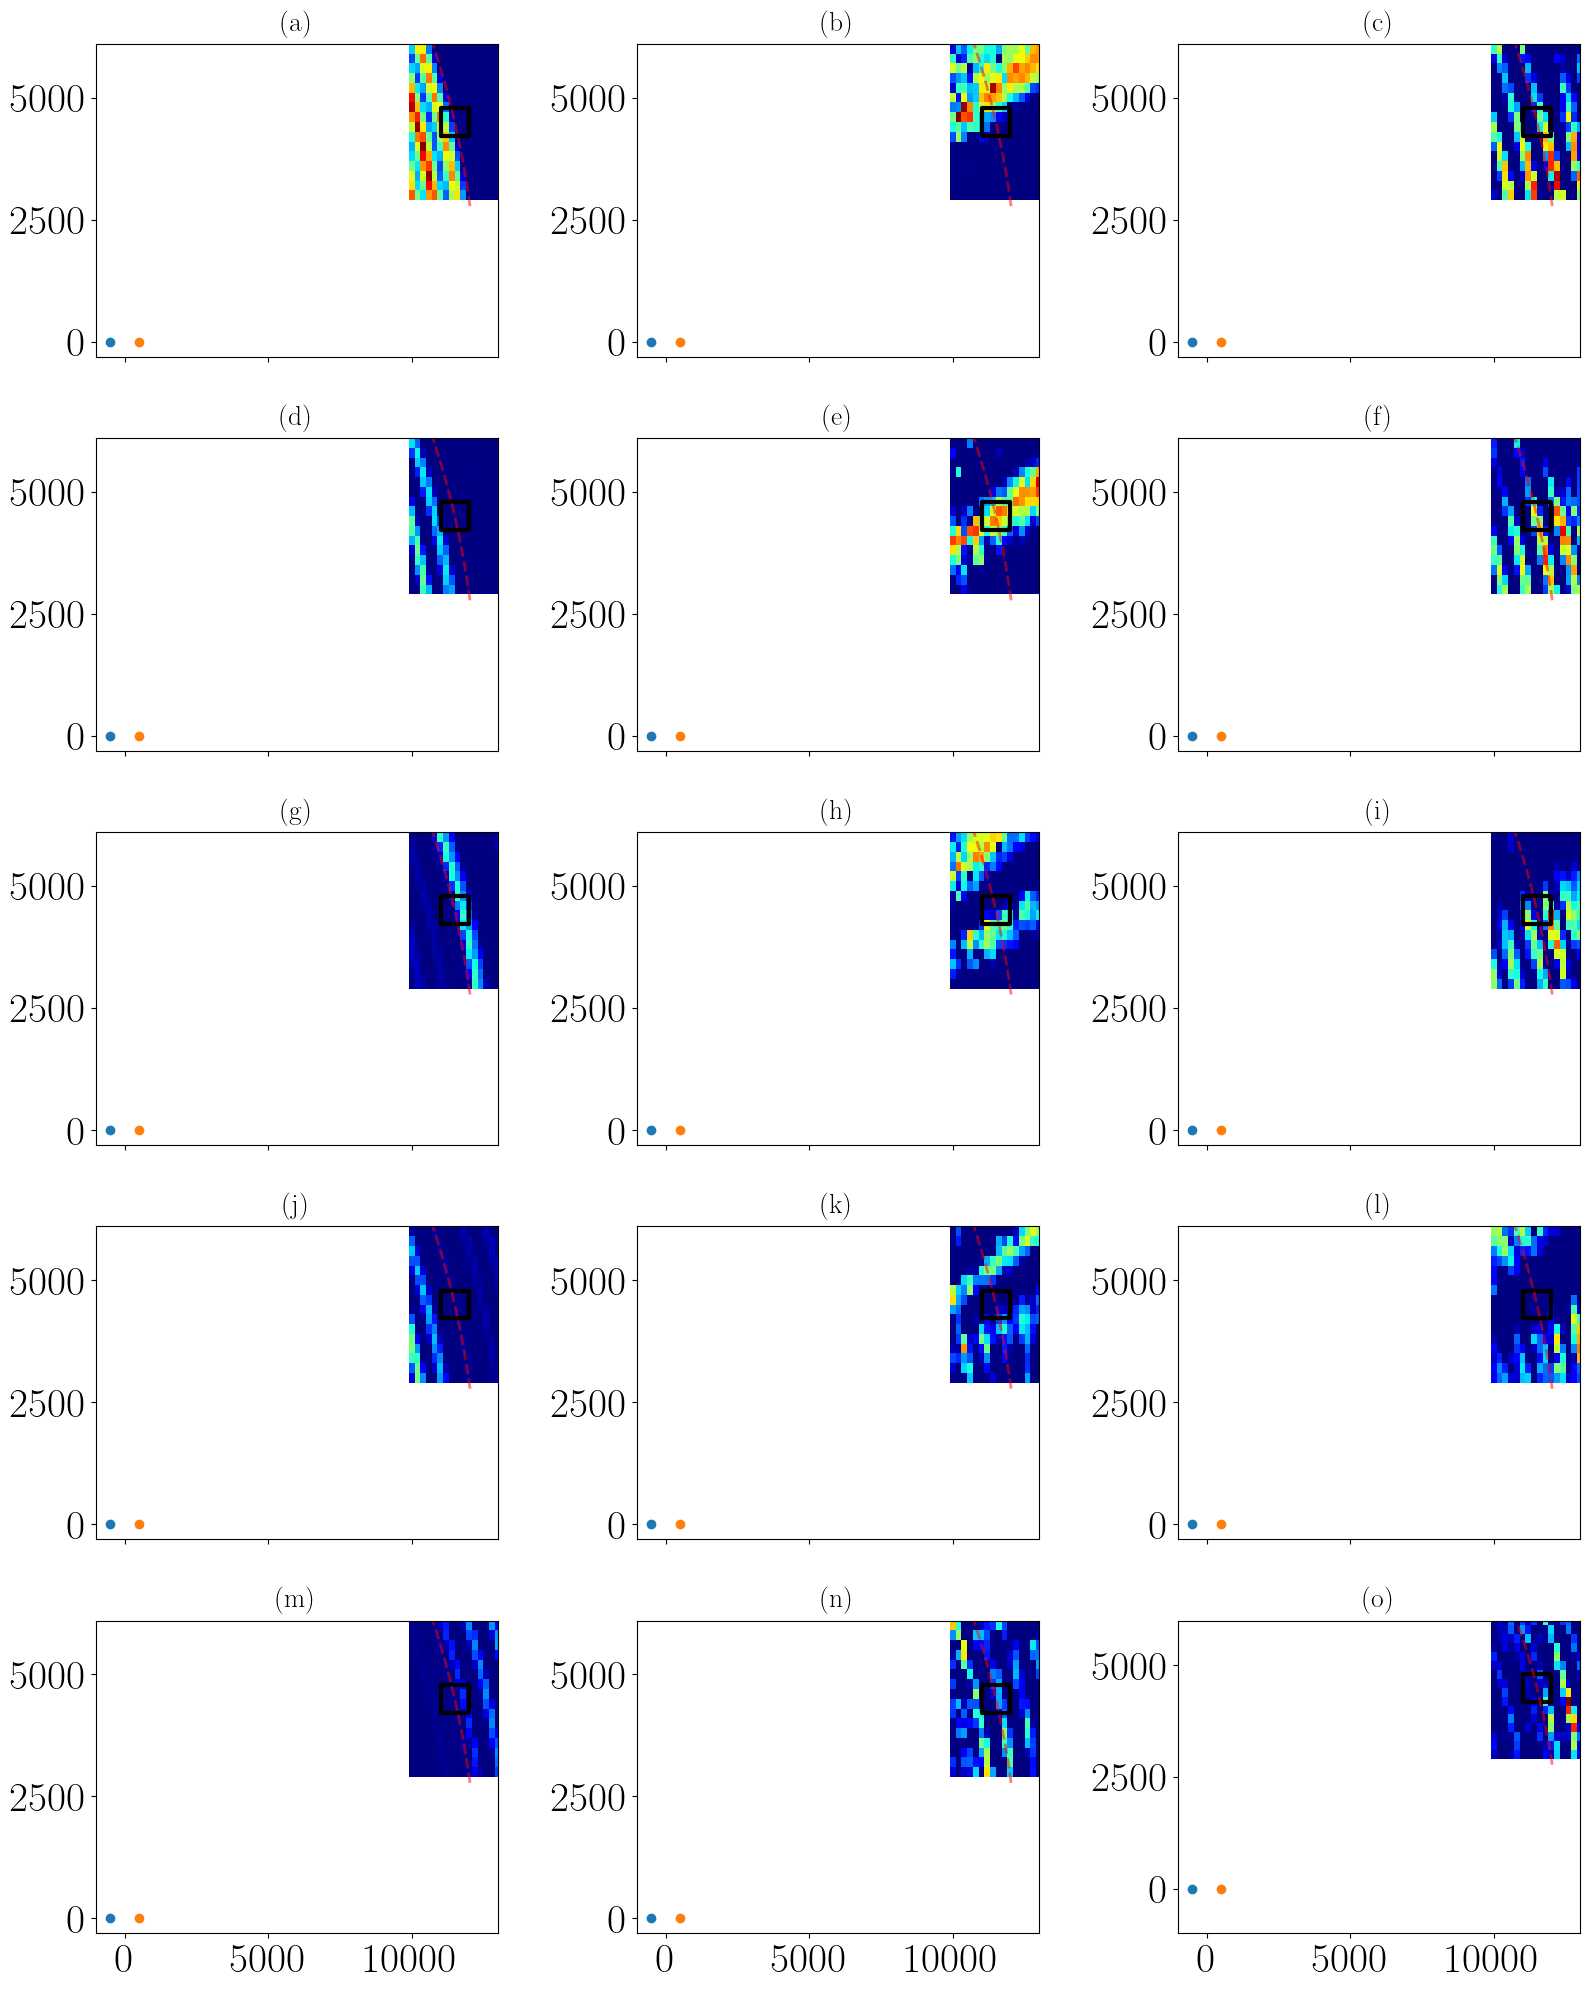

In [18]:
fig, axs = plt.subplots(n_components, 3, figsize=(16, 4*n_components), sharex=True)
# axs = axs.flatten()
for i in range(n_components):
    axs[i, 0].pcolormesh(x, y, coords_isomap_gamma[..., i], cmap="bwr", vmin=-1, vmax=1)
    axs[i, 1].pcolormesh(x, y, coords_isompa_pi[..., i], cmap="bwr", vmin=-1, vmax=1)
    axs[i, 2].pcolormesh(x, y, coords_isompa_dcf[..., i], cmap="bwr", vmin=-1, vmax=1)


for ax in axs.flatten():
    ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

plt.xlim(-d12, np.max(x))
plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2 * r0,
        height=2 * r0,
        angle=0,
        theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
        theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--",
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

### Rang des matrices de coordonnées en projection et matrice d'origine 

In [19]:
shape = rr1.shape + (freq.size,)
gamma_21_rr_grid = gamma_21_rr.T.reshape(shape)

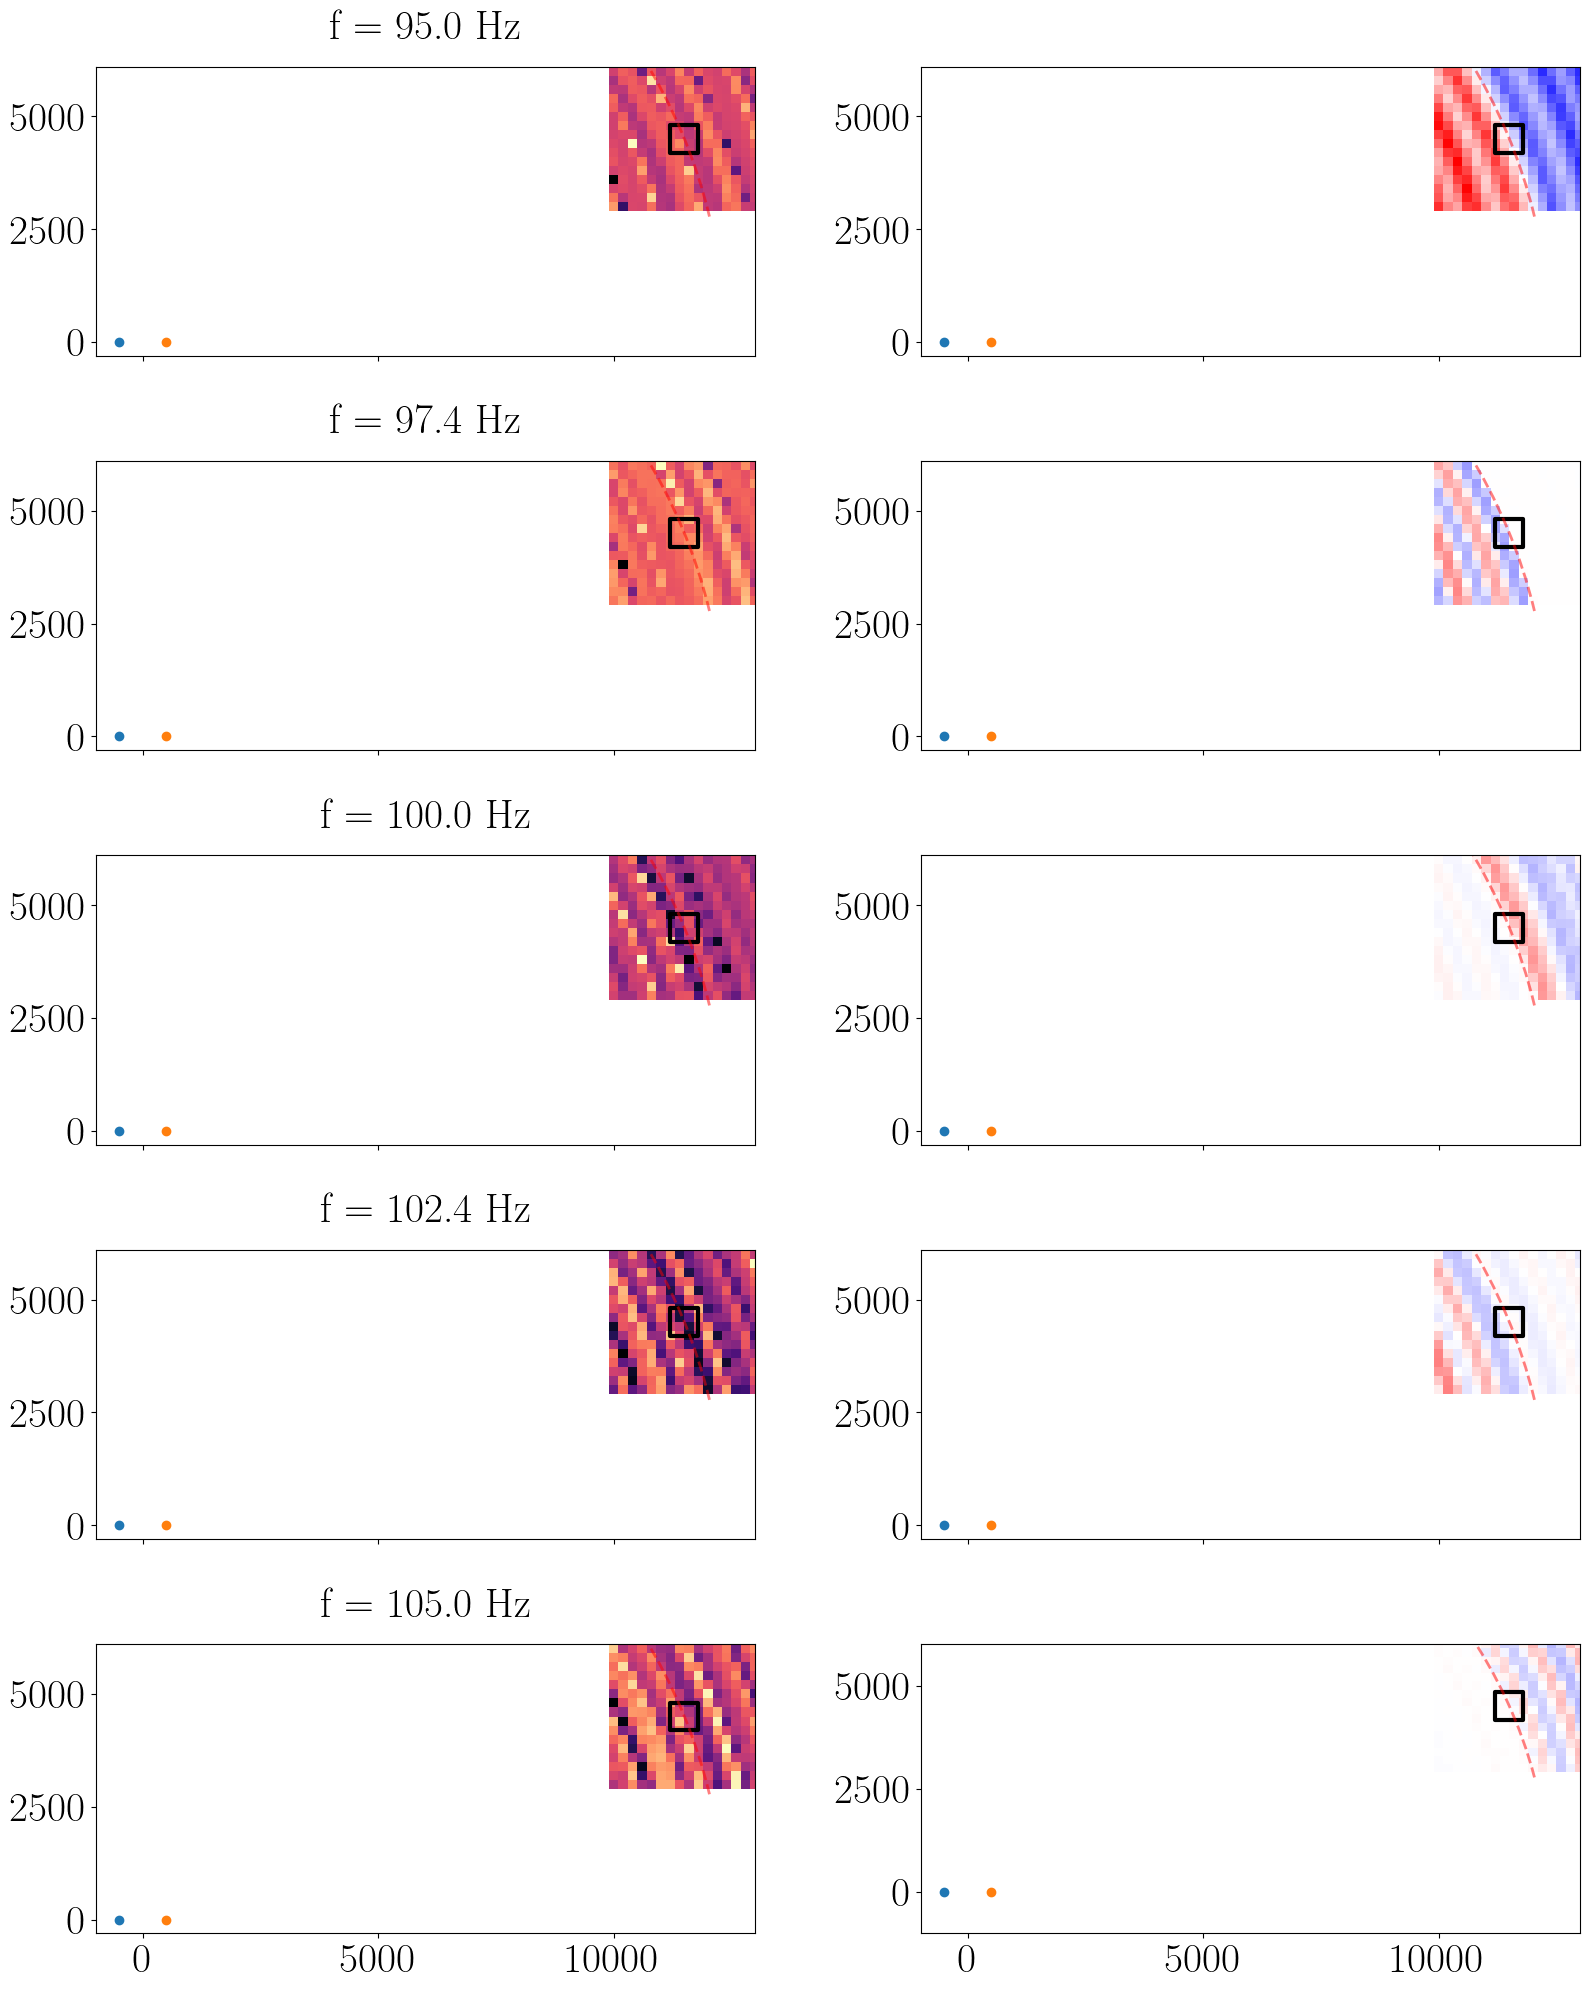

In [20]:
fig, axs = plt.subplots(n_components, 2, figsize=(16, 4 * n_components), sharex=True)
# axs = axs.flatten()
freq_plot = [95, 97.5, 100, 102.5, 105]
for i in range(n_components):
    idx_f = np.argmin(np.abs(freq-freq_plot[i]))
    axs[i, 0].pcolormesh(x, y, gamma_21_rr_grid[..., idx_f], cmap="magma")
    axs[i, 0].set_title(f"f = {freq[idx_f]} Hz")
    axs[i, 1].pcolormesh(x, y, coords_isomap_gamma[..., i], cmap="bwr", vmin=-1, vmax=1)


for ax in axs.flatten():
    ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

plt.xlim(-d12, np.max(x))
plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2 * r0,
        height=2 * r0,
        angle=0,
        theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
        theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--",
    )

    ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

# Interpolation par apprentissage de variété 

## Génération d'un jeu de données éparse pour la librarie 

1


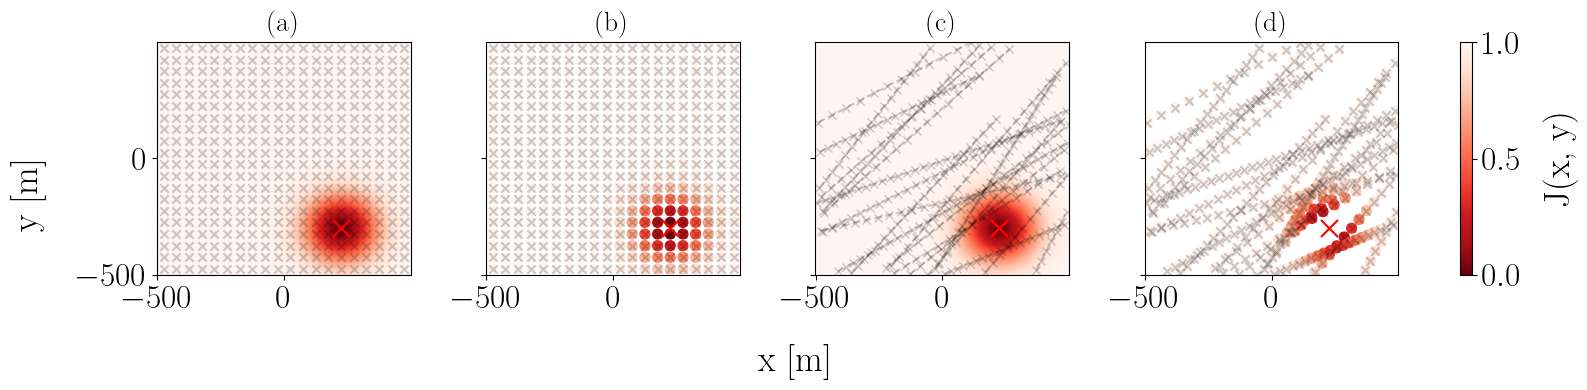

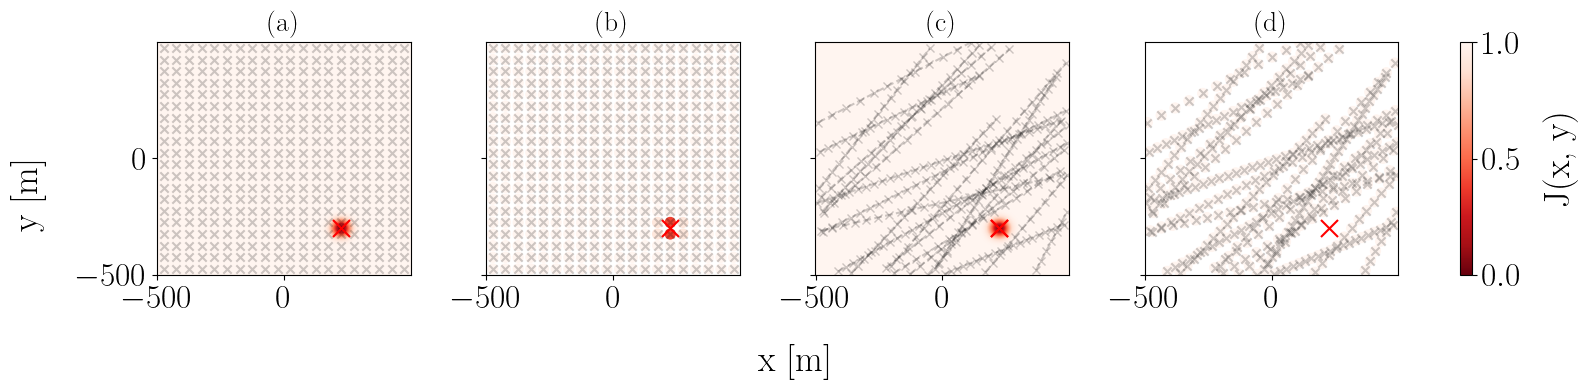

In [21]:
from illustration.mfp.mfp_measured.mfp_processor_and_grid_resolution import generate_ship_tracks

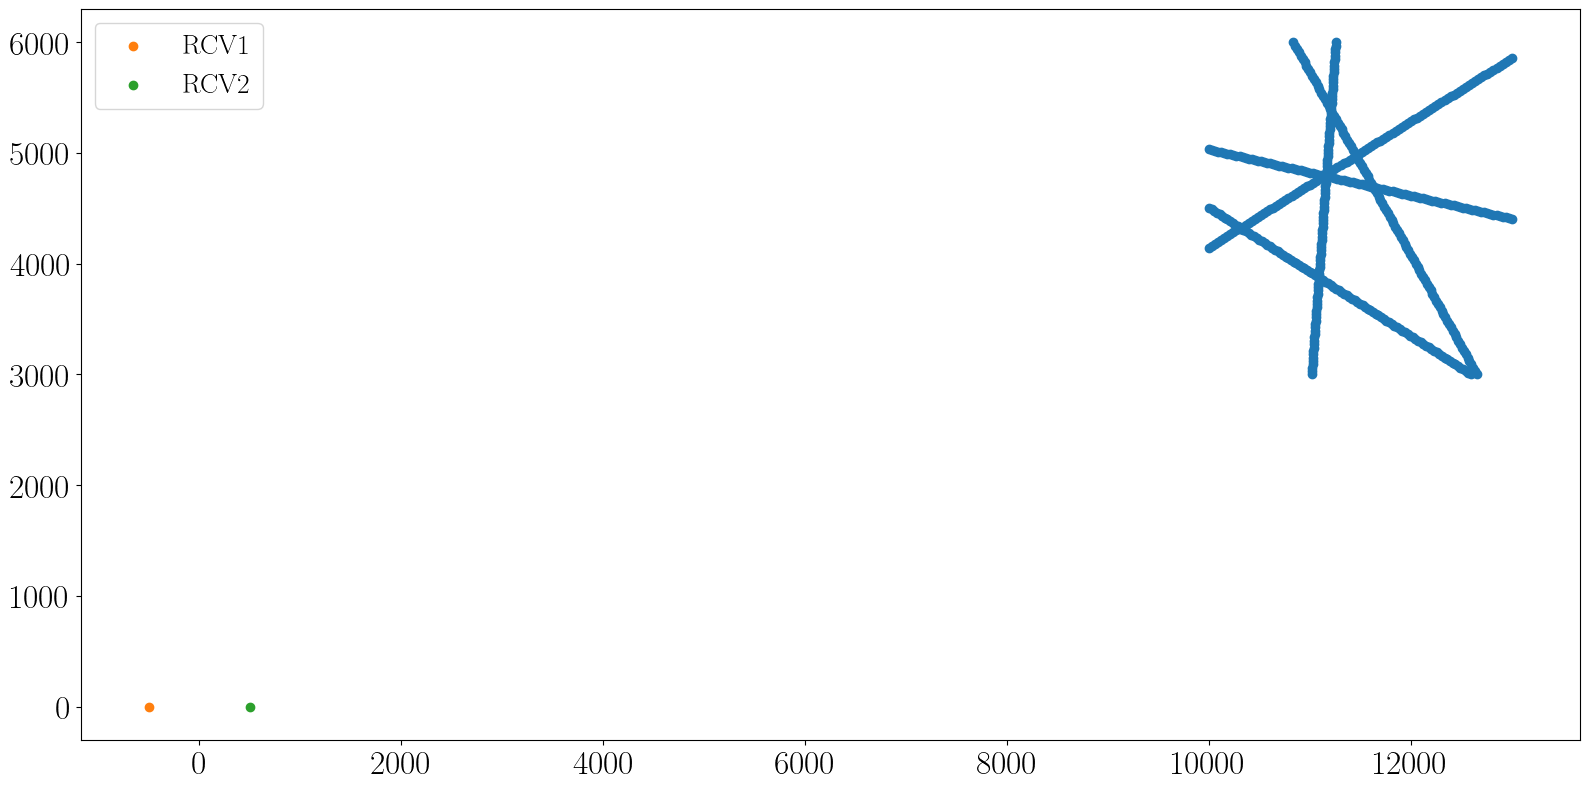

In [22]:
random_seed = 2026
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=15, npt=100, random_seed=random_seed)      # OK pour 15
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=10, npt=100, random_seed=random_seed)        # Ok pour 10
x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=100, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=200, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5


x_lib_sparse = np.concat(x_tracks)
y_lib_sparse = np.concat(y_tracks)

plt.scatter(
    x_lib_sparse,
    y_lib_sparse,
)
plt.scatter(
    x_rcv1,
    y_rcv1,
    label="RCV1",
)
plt.scatter(
    x_rcv2,
    y_rcv2,
    label="RCV2",
)
plt.legend()

## Calcul des RTFs 

In [23]:
rr1_lib_sparse = np.sqrt((x_lib_sparse - x_rcv1) ** 2 + (y_lib_sparse - y_rcv1) ** 2)
rr2_lib_sparse = np.sqrt((x_lib_sparse - x_rcv2) ** 2 + (y_lib_sparse - y_rcv2) ** 2)

# Green's fct on the 2D grid
rr1_lib_sparse_flat = rr1_lib_sparse.flatten()
gf_rr1_sparse = pekeris_green_fct(
    freq, c1, c2, rho1, rho2, attn2, d, z_s, z, rr1_lib_sparse_flat
)
rr2_lib_sparse_flat = rr2_lib_sparse.flatten()
gf_rr2_sparse = pekeris_green_fct(
    freq, c1, c2, rho1, rho2, attn2, d, z_s, z, rr2_lib_sparse_flat
)

# Gamma
pi_21_rr_sparse = gf_rr2_sparse / gf_rr1_sparse
gamma_21_rr_sparse = 20 * np.log10(np.abs(pi_21_rr_sparse))

# Intercorr
c21_rr_sparse = gf_rr1_sparse * np.conj(gf_rr2_sparse)

C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:326: RuntimeWarning: invalid value encountered in sqrt
  idx_krm_lt_k2, np.sqrt(k2**2 - krm**2), 1j * np.sqrt(krm**2 - k2**2)
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:618: RuntimeWarning: divide by zero encountered in divide
  lambd = c / f
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:582: RuntimeWarning: invalid value encountered in divide
  (1j * alpha_2_2d * omega_2d)
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:518: RuntimeWarning: invalid value encountered in sqrt
  / np.sqrt(krm[..., np.newaxis])
C:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:516: RuntimeWarning: invalid value encountered in divide
  Am[..., np.newaxis]
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28956\2385114335.py:15: RuntimeWarning: invalid value encountered in divide
  pi_21_rr_sparse = gf_rr2_sparse / gf_rr1_sparse


In [24]:
pi_21_rr_sparse.shape, x_lib_sparse.shape, y_lib_sparse.shape, rr1_lib_sparse.shape, rr2_lib_sparse.shape, freq.shape

((751, 500), (500,), (500,), (500,), (500,), (751,))

## Apprentissage de variété 

In [25]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr_sparse.T  # (n_sample, n_features) = (n_pos, nfreq)

# Subsample
# gamma_ = gamma_[::10, :]

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# ### RTF (Pi) ###
# Learn manifold and project data in target dimension
pi_21_rr_ = pi_21_rr_sparse.T  # (n_pos, nfreq)

# Calc theta with pi
inner_prod = np.nansum(
    pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
)
norm_a = np.sqrt(
    np.nansum(
        pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[np.newaxis, :, :], axis=-1
    )
)
norm_b = np.sqrt(
    np.nansum(
        pi_21_rr_[:, np.newaxis, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
    )
)
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

### DCF ###
c12_ = c21_rr_sparse.T
# Subsample to reduce memory
# c12_ = c12_[::2, :]
dist_mat = np.abs(
    np.nansum(
        c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
        axis=-1,
    )
)
dist_mat = dist_mat / np.max(dist_mat)
dist_mat_dcf = 1 - dist_mat

In [26]:
n_components = 5
n_neighbors = 10
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# ### RTF (Pi) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
coords_isomap_pi = coords_isomap_pi / np.max(np.abs(coords_isomap_pi))

# ### DCF ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_dcf = isomap_obj.fit_transform(dist_mat_dcf)
coords_isomap_dcf = coords_isomap_dcf / np.max(np.abs(coords_isomap_dcf))

In [27]:
# Reshape coords to 2D grid
shape = rr1_lib_sparse.shape + (n_components,)
coords_isomap_gamma = coords_isomap_gamma.reshape(shape)
coords_isomap_pi = coords_isomap_pi.reshape(shape)
coords_isomap_dcf = coords_isomap_dcf.reshape(shape)

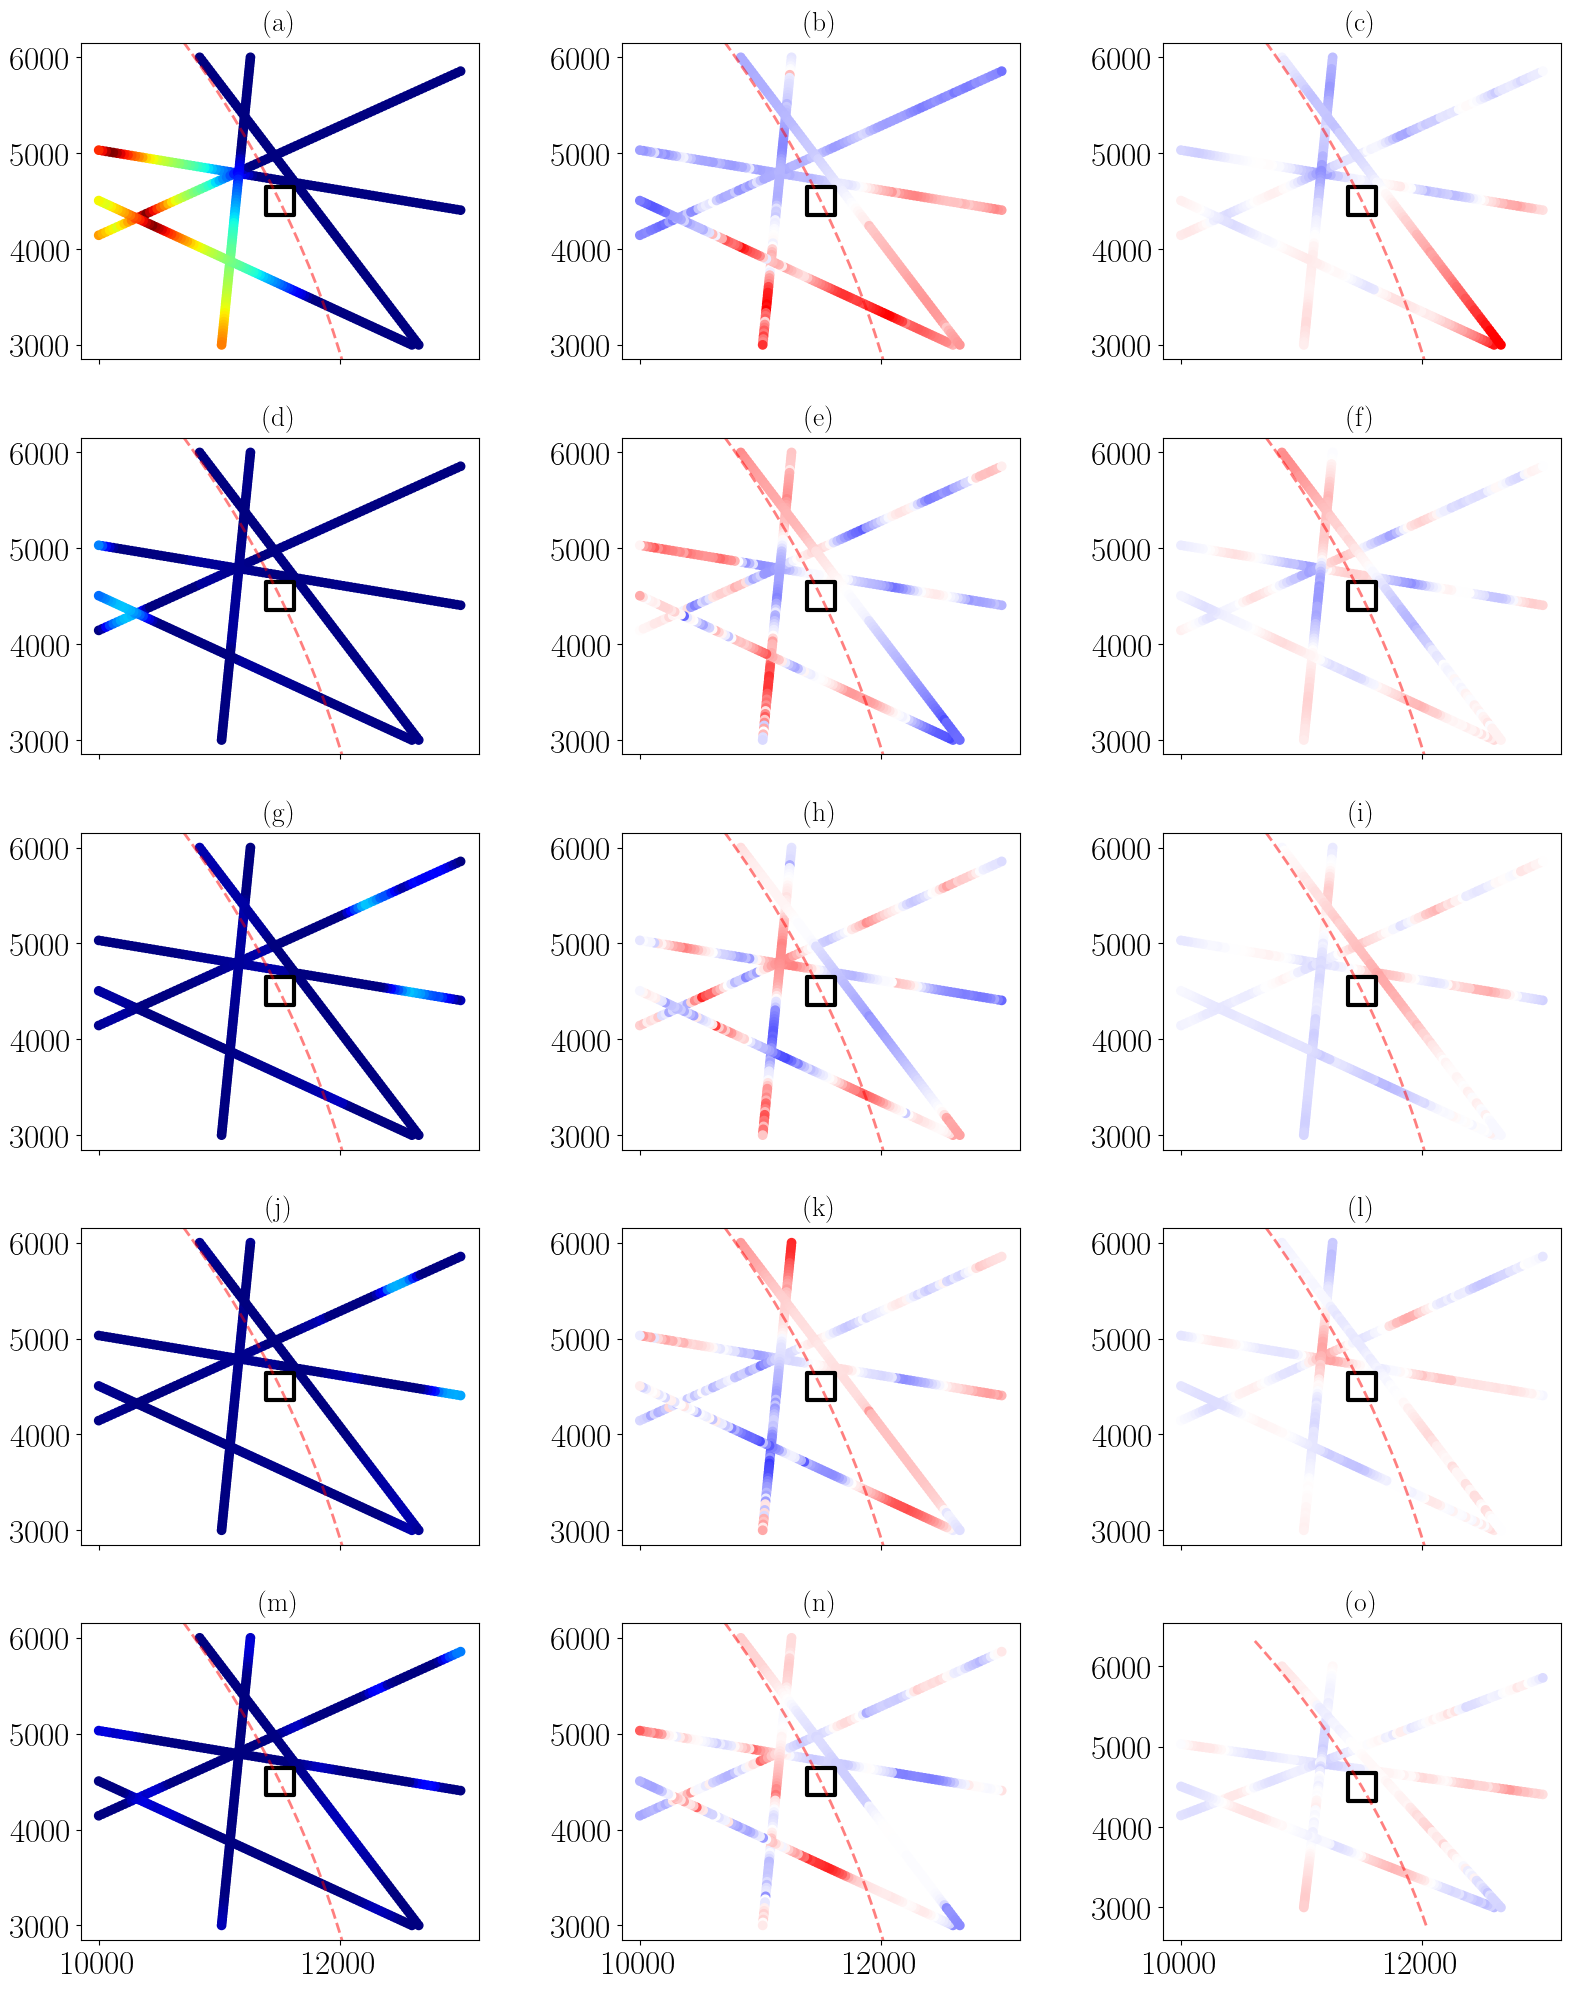

In [28]:
fig, axs = plt.subplots(n_components, 3, figsize=(16, 4*n_components), sharex=True)
# axs = axs.flatten()
for i in range(n_components):
    axs[i, 0].scatter(x_lib_sparse, y_lib_sparse, c=coords_isomap_gamma[..., i], cmap="jet", vmin=0, vmax=1)
    axs[i, 1].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_pi[..., i],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    axs[i, 2].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_dcf[..., i],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2 * r0,
        height=2 * r0,
        angle=0,
        theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
        theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--",
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

## Interpolation des coordonnées en projection 

In [29]:
xx_flat = xx.flatten()
yy_flat = yy.flatten()

dx_grid_lib = xx_flat[:, np.newaxis] - x_lib_sparse[np.newaxis, :]  # (n_xx, n_xlib)
dy_grid_lib = yy_flat[:, np.newaxis] - y_lib_sparse[np.newaxis, :]  # (n_yy, n_ylib)
r_grid_lib = np.sqrt(dx_grid_lib**2 + dy_grid_lib**2)
r_grid_lib.shape

# # check this is okay
# i, j = -1, -1
# print(
#     f"Distance from grid point of coords e={xx_flat[i]}, n={yy_flat[i]} : {r_grid_lib[i, :]}"
# )
# # Non vectorized calc for comparison
# x_test = xx_flat[i]
# y_test = yy_flat[i]
# r_test = np.sqrt((x_test - x_lib_sparse) ** 2 + (y_test - y_lib_sparse) ** 2)
# print(np.allclose(r_test, r_grid_lib[i, :]))

(256, 500)

In [30]:
# Interpolate each coords in low dim
i = 0
power = 10

low_dim = 5
coords_low_dim = coords_isomap_gamma[:, :low_dim]
coords_low_dim_grid = np.empty((xx_flat.shape[0], coords_low_dim.shape[1]))
for i in range(low_dim):
    psi_i = coords_low_dim[:, i]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(psi_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    psi_i_interp = numerator / weights

    coords_low_dim_grid[:, i] = psi_i_interp

# Reshape
coords_low_dim_grid = np.reshape(
    coords_low_dim_grid, xx.shape + (coords_low_dim_grid.shape[1],)
)

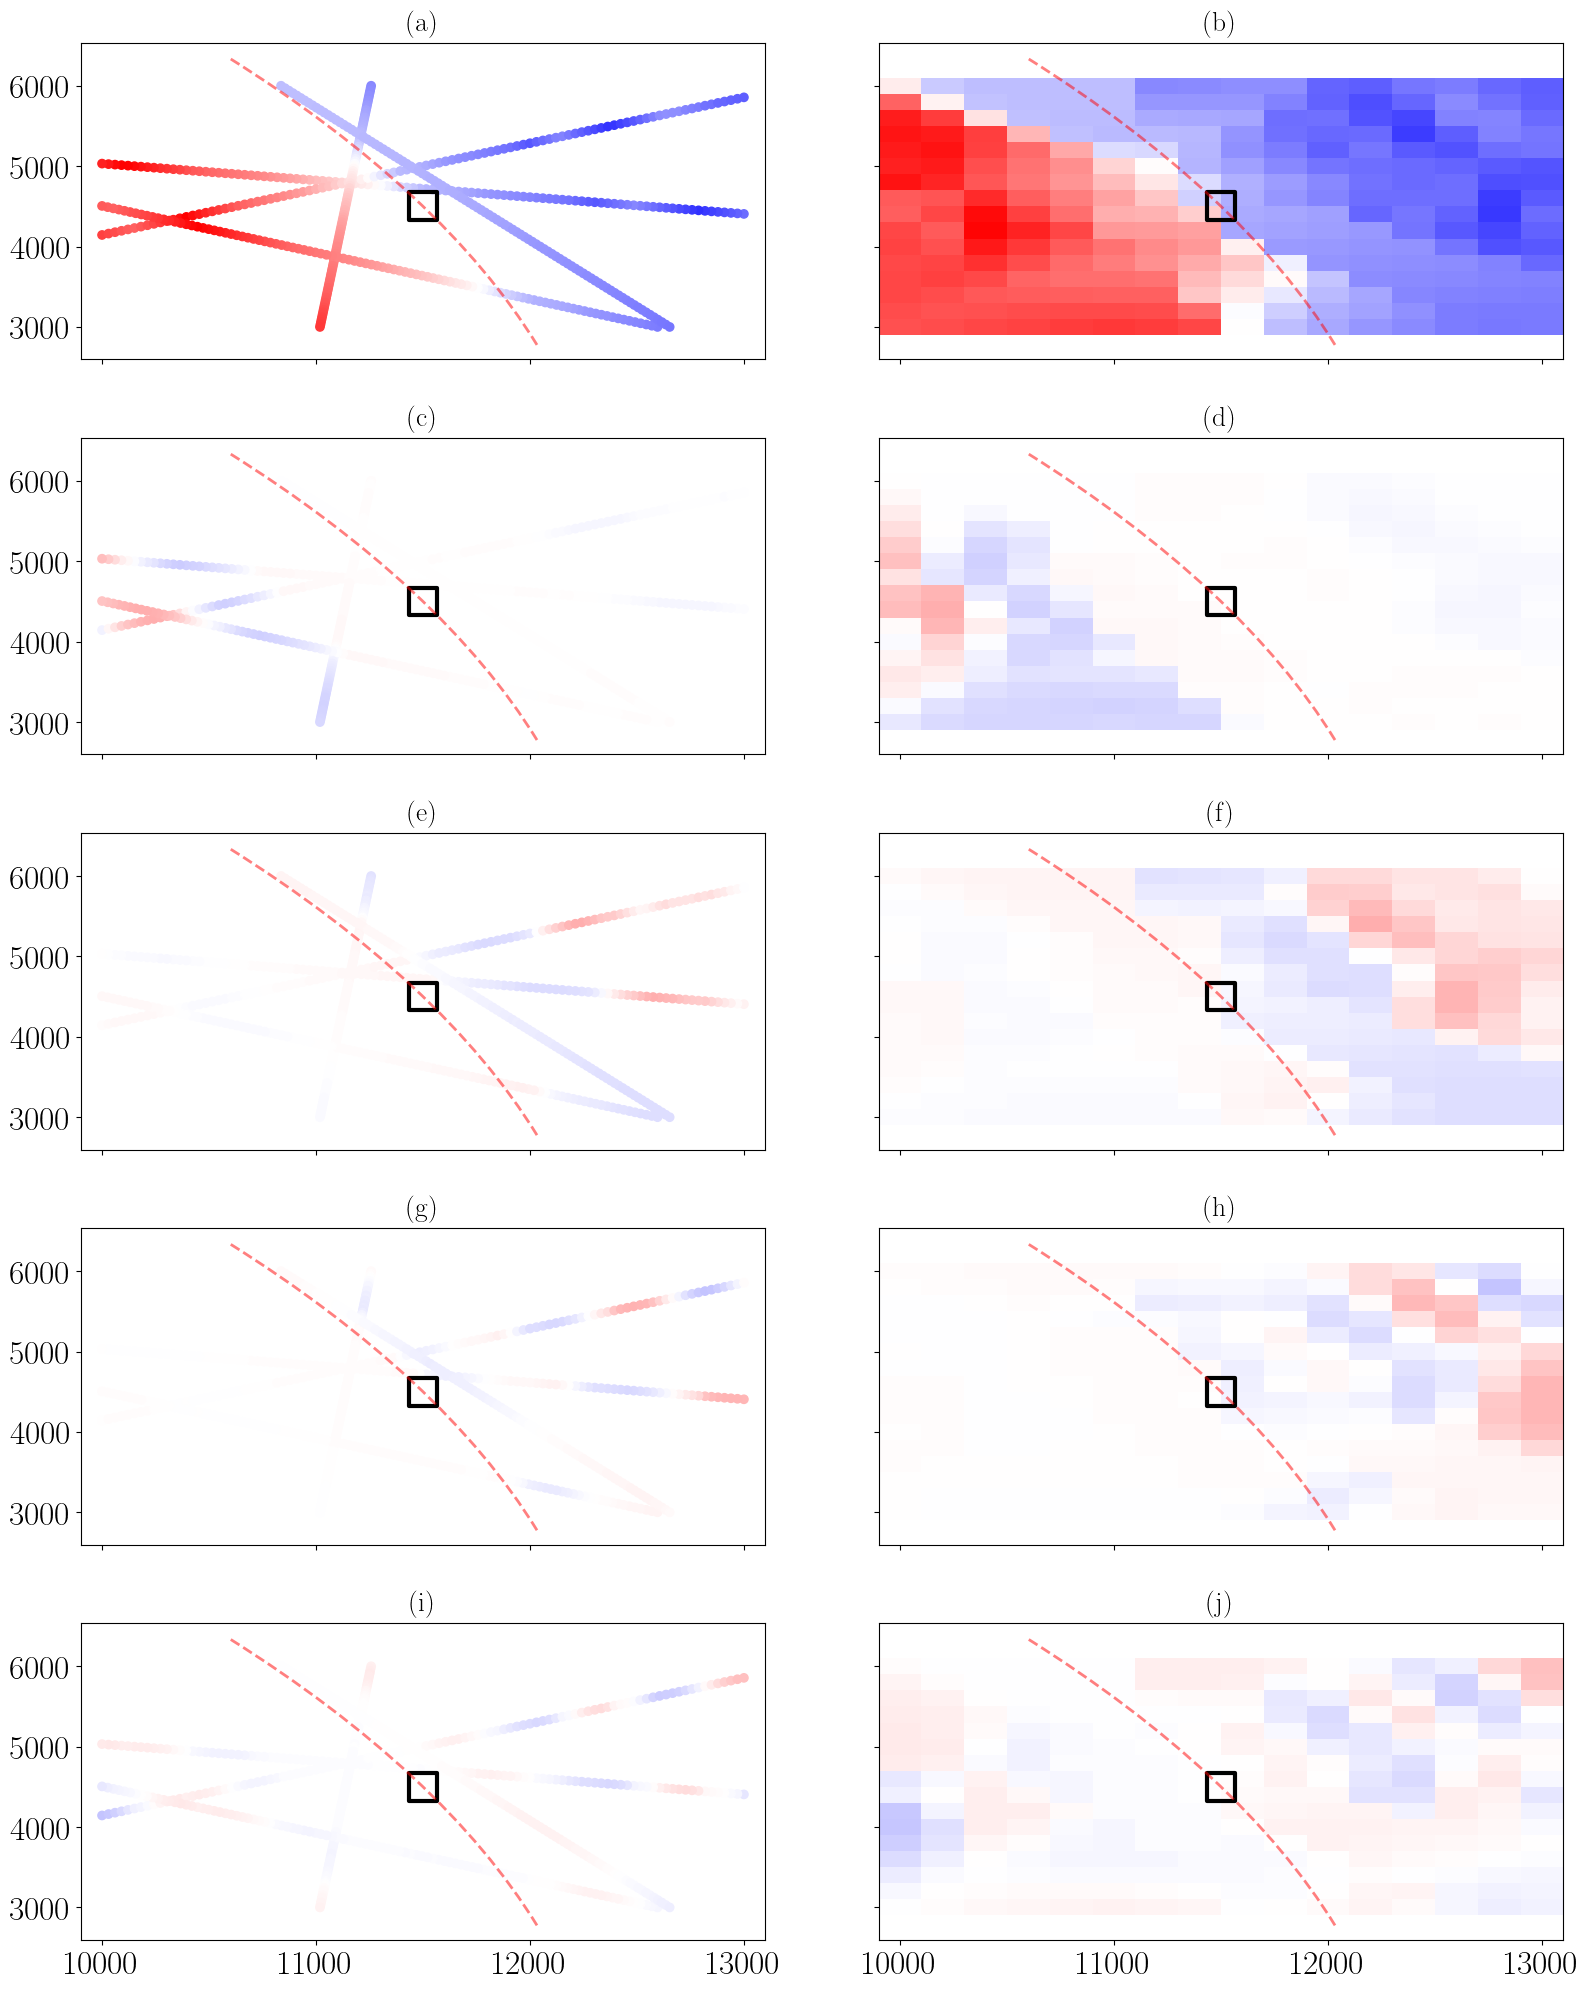

In [31]:
fig, axs = plt.subplots(n_components, 2, figsize=(16, 4 * n_components), sharex=True, sharey=True)
# axs = axs.flatten()
for i in range(n_components):

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_gamma[..., i],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )

    psi_i_interp = coords_low_dim_grid[:, :, i]
    axs[i, 1].pcolormesh(
        x,
        y,
        psi_i_interp,
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2 * r0,
        height=2 * r0,
        angle=0,
        theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
        theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--",
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

## Localisation avec la librairie interpolée 

In [32]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
coords_low_dim_X0 = coords_low_dim_grid[idx_x0, idx_y0, :]

In [33]:
d_L2_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim_grid - coords_low_dim_X0) ** 2,
        axis=-1,
    )
)

ind_min_L2_low_dim = np.argmin(d_L2_low_dim)
xmin_L2_low_dim, ymin_L2_low_dim = (
    xx.flatten()[ind_min_L2_low_dim],
    yy.flatten()[ind_min_L2_low_dim],
)

In [34]:
# # dist_L1 = calc_gamma_dist(
# #     gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L1"
# # )
# # dist_L2 = calc_gamma_dist(
# #     gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L2"
# # )
# # # Calc theta with gamma
# # dist_theta_gamma = calc_gamma_dist(
# #     gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="theta"
# # )
# # With abs(pi)
# # dist_theta_gamma = calc_gamma_dist(
# #     gamma_a=np.abs(pi_21_r0), gamma_b=np.abs(pi_21_rr), dist_type="theta"
# # )

# # # Calc theta with pi
# # inner_prod = np.nansum(pi_21_r0 * np.conj(pi_21_rr), axis=0)
# # norm_a = np.sqrt(np.nansum(pi_21_r0 * np.conj(pi_21_r0), axis=0))
# # norm_b = np.sqrt(np.nansum(pi_21_rr * np.conj(pi_21_rr), axis=0))
# # # Clip to [-1, 1] for stability
# # cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
# # dist_theta = 1 - cos_angle  #  to [0, 1]
# # # dist = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# dist_L1 /= np.max(dist_L1)
# dist_L2 /= np.max(dist_L2)
# # # NOTE Should we normalize ? -> for a fair comparison each dist must have the same dynamic range ?
# # dist_theta /= np.max(dist_theta)
# dist_theta_gamma /= np.max(dist_theta_gamma)

# # reshape
# dist_theta_gamma = dist_theta_gamma.reshape(rr1_flat.shape)

# # dist_theta = dist_theta.reshape(rr1.shape)
# # dist_c = dist_c.reshape(rr1.shape)
# # Get min
# # ind_min = np.argmin(dist_theta)
# # xmin, ymin = xx.flatten()[ind_min], yy.flatten()[ind_min]
# ind_min_gamma = np.argmin(dist_theta_gamma)
# xmin_gamma, ymin_gamma = xx.flatten()[ind_min_gamma], yy.flatten()[ind_min_gamma]
# # ind_min_c = np.argmin(dist_c)
# # xmin_c, ymin_c = xx.flatten()[ind_min_c], yy.flatten()[ind_min_c]


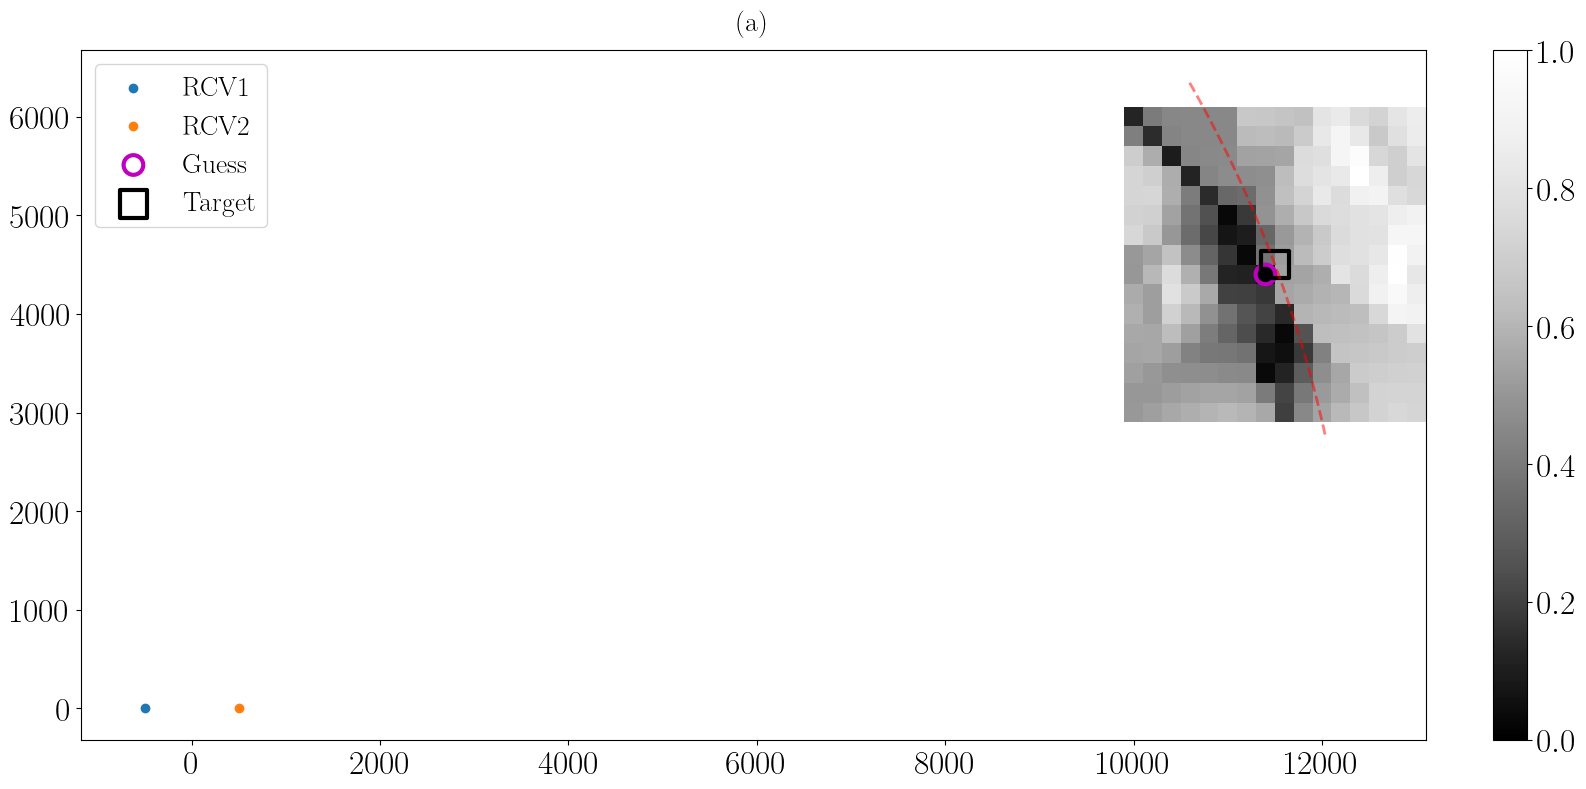

In [35]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, d_L2_low_dim, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_L2_low_dim,
    ymin_L2_low_dim,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2*r0,
        height=2*r0,
        angle=0,
        theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
        theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--"
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

## Comparaison avec une interpolation directe sur le vecteur de RTF 

In [36]:
gamma_21_rr_sparse.shape, freq.size, xx_flat.shape[0]

((751, 500), 751, 256)

In [37]:
# Interpolate each coords in low dim
power = 10

gamma_21_rr_sparse_grid = np.empty((xx_flat.shape[0], gamma_21_rr_sparse.shape[0]))
for ifreq in range(freq.size):
    gamma_freq_i = gamma_21_rr_sparse[ifreq, :]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(gamma_freq_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    gamma_freq_i_interp = numerator / weights

    gamma_21_rr_sparse_grid[:, ifreq] = gamma_freq_i_interp

# Reshape
gamma_21_rr_sparse_grid = np.reshape(
    gamma_21_rr_sparse_grid, xx.shape + (gamma_21_rr_sparse_grid.shape[1],)
)

In [38]:
gamma_21_rr_sparse.shape

(751, 500)

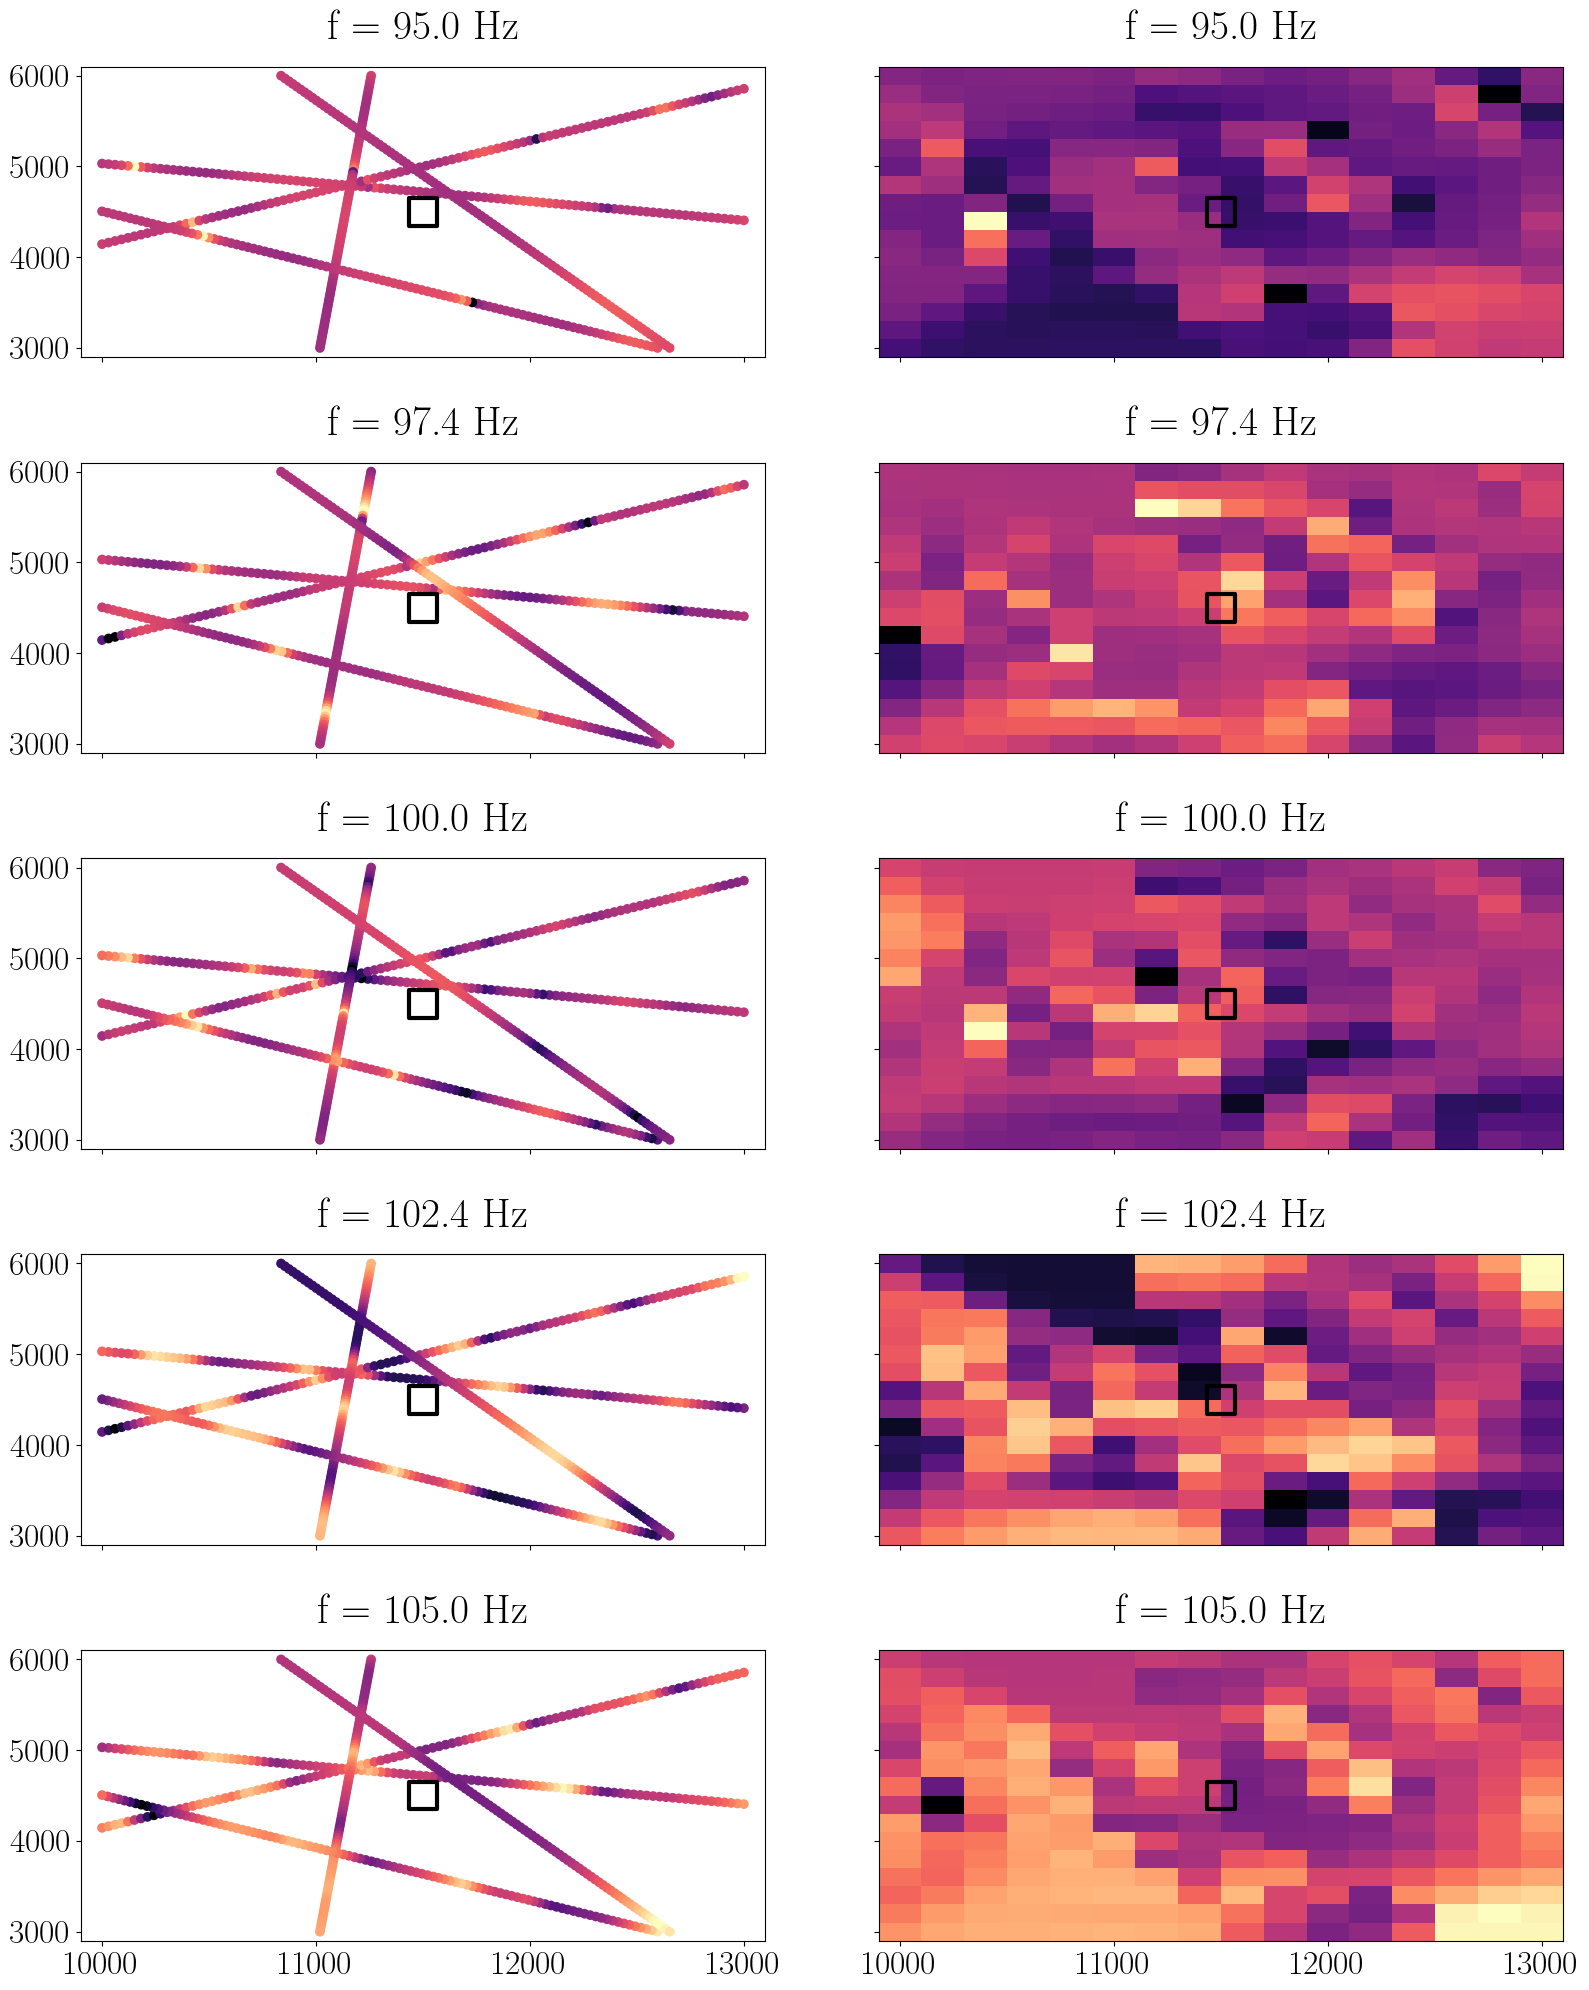

In [39]:
fig, axs = plt.subplots(n_components, 2, figsize=(16, 4 * n_components), sharex=True, sharey=True)
# axs = axs.flatten()

freq_plot = [95, 97.5, 100, 102.5, 105]
for i in range(len(freq_plot)):
    idx_f = np.argmin(np.abs(freq - freq_plot[i]))

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=gamma_21_rr_sparse[idx_f, :],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    # psi_i_interp = coords_low_dim_grid[:, :, idx_f]
    axs[i, 1].pcolormesh(
        x,
        y,
        gamma_21_rr_sparse_grid[:, :, idx_f],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    axs[i, 0].set_title(f"f = {freq[idx_f]} Hz")
    axs[i, 1].set_title(f"f = {freq[idx_f]} Hz")
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

In [40]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
gamma_21_rr_sparse_grid_r0 = gamma_21_rr_sparse_grid[idx_x0, idx_y0, :]

In [41]:
gamma_a = gamma_21_rr_sparse_grid_r0[:, np.newaxis]
gamma_b = gamma_21_rr_sparse_grid.reshape(
    gamma_21_rr_sparse_grid.shape[0] * gamma_21_rr_sparse_grid.shape[1],
    gamma_21_rr_sparse_grid.shape[2],
).T
print(gamma_a.shape, gamma_b.shape)
dist_theta_gamma_sparse_grid = calc_gamma_dist(gamma_a=gamma_a, gamma_b=gamma_b, dist_type="theta")
dist_theta_gamma_sparse_grid /= np.max(dist_theta_gamma_sparse_grid)

ind_min_gamma_sparse_grid = np.argmin(dist_theta_gamma_sparse_grid)
xmin_gamma_sparse_grid, ymin_gamma_sparse_grid = (
    xx.flatten()[ind_min_gamma_sparse_grid],
    yy.flatten()[ind_min_gamma_sparse_grid],
)

(751, 1) (751, 256)


In [42]:
dist_theta_gamma_sparse_grid = dist_theta_gamma_sparse_grid.reshape(rr1.shape)

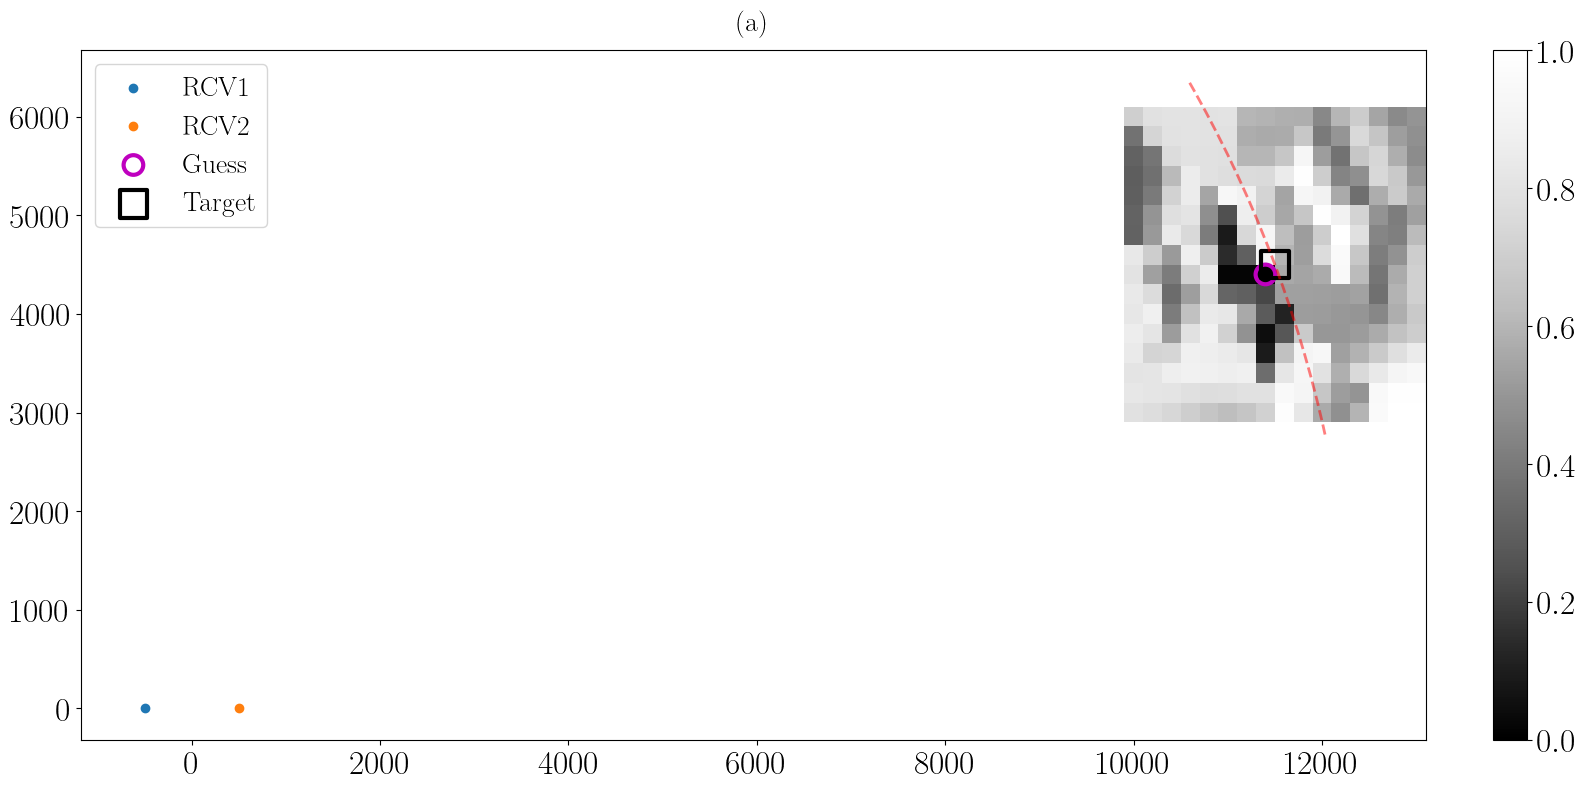

In [43]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, dist_theta_gamma_sparse_grid, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_gamma_sparse_grid,
    ymin_gamma_sparse_grid,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
from matplotlib.patches import Arc

for ax in axs.flatten():

    arc0 = Arc(
        (0, 0),
        width=2*r0,
        height=2*r0,
        angle=0,
        theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
        theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
        color="r",
        alpha=0.5,
        linewidth=2,
        linestyle="--"
    )

    ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)